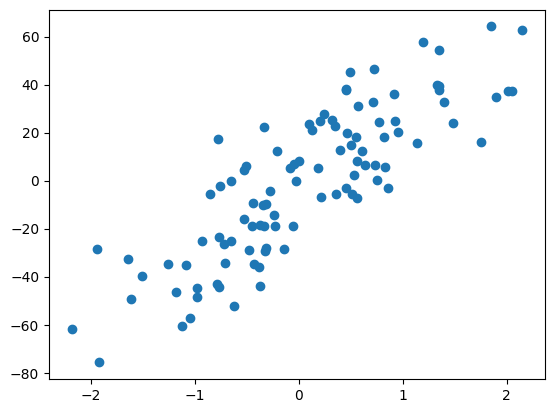

In [24]:
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import cross_val_score

X,y = make_regression(n_samples=100, n_features=1, n_informative=1, n_targets=1,noise=20,random_state=13)


plt.scatter(X,y)

In [31]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(X,y, test_size=0.2, random_state=2)

scikit learn ke liner regression apply kar ke acctual result fatch kar raha hu 

In [32]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

In [33]:
lr.fit(x_train,y_train)
print(lr.coef_)
print(lr.intercept_)

[28.12597332]
-2.2710144261783825


In [35]:
y_pred = lr.predict(x_test)
from sklearn.metrics import r2_score
r2_score(y_test, y_pred)

0.6345158782661012

In [34]:
np.mean(cross_val_score(lr, X, y, scoring='r2', cv= 10))

np.float64(0.6375011587464419)

eek class banayenge jo hame given data ke intercept data dega 

In [28]:
class GDRergressor:

    def __init__(self, learning_rate, epochs):
        self.m = 100
        self.b = -120
        self.lr = learning_rate
        self.epochs = epochs

    def fit(self, X, y):
        # calculate karna hai b using GD 
        for i in range(self.epochs):
            loss_slop_b = -2 * np.sum(y - self.m*X.ravel() - self.b)
            loss_slope_m = -2 * np.sum((y - self.m*X.ravel() - self.b)*X.ravel())
            self.b = self.b - (self.lr * loss_slop_b)
            self.m = self.m - (self.lr * loss_slope_m)
            # print(loss_slope_m, self.b)

        print(self.m, self.b)

    def predict(self, X):
        return self.m * X + self.b
        

In [38]:
y_pred = lr.predict(x_test)
from sklearn.metrics import r2_score
r2_score(y_test, y_pred)

0.6345158782661012

In [39]:
gd = GDRergressor(0.001, 50)

gd.fit(x_train, y_train) 

28.159367347119066 -2.3004574196824854


In [40]:
y_pred = lr.predict(x_test)
from sklearn.metrics import r2_score
r2_score(y_test, y_pred)

0.6345158782661012

In [ ]:
from sklearn.datasets import make_regression

import numpy as np
import matplotlib.pyplot as plt
# %matplotlib notebook
from matplotlib.animation import FuncAnimation
import matplotlib.animation as animation
X,y = make_regression(n_samples=100, n_features=1, n_informative=1, n_targets=1,noise=20,random_state=13)
plt.scatter(X,y)

<IPython.core.display.Javascript object>

In [ ]:
b = -120
m = 100
lr = 0.001
all_b = []
all_m = []
all_cost = []

epochs = 30

for i in range(epochs):
    slope_b = 0
    slope_m = 0
    cost = 0
    for j in range(X.shape[0]):
        slope_b = slope_b - 2*(y[j] - (m * X[j]) -  b)
        slope_m = slope_m - 2*(y[j] - (m * X[j]) -  b)*X[j]
        cost = cost + (y[j] - m * X[j] -b) ** 2

    b = b - (lr * slope_b)
    m = m - (lr * slope_m)
    all_b.append(b)
    all_m.append(m)
    all_cost.append(cost)

In [ ]:
fig, ax = plt.subplots(figsize=(9,5))
#fig.set_tight_layout(True)

x_i = np.arange(-3, 3, 0.1)
y_i = x_i*(-27) -150
ax.scatter(X, y)
line, = ax.plot(x_i, x_i*50 - 4, 'r-', linewidth=2)

def update(i):
    label = 'epoch {0}'.format(i + 1)
    line.set_ydata(x_i*all_m[i] + all_b[i])
    ax.set_xlabel(label)
    # return line, ax

anim = FuncAnimation(fig, update, repeat=True, frames=epochs, interval=500)

#f = r"animation4.gif" 
#writergif = animation.PillowWriter(fps=2) 
#anim.save(f, writer=writergif)

<IPython.core.display.Javascript object>